# Extended Data Fig. 7: neighbourhood size of the spatial smoothing

Mouse brain Visium with 1-10 neighbourhood rings (`n_neighbors` = 6 x ring) as in `12_visium_platform_n_neighbours`, scored with
EnrichMap (null). Every panel uses the same gene sets, defined once below: `Pyramidal_layer_top10` and
`Striatum_top10` (10 genes each, the signatures of Extended Data Fig. 2). Panels: a distance to the k-th nearest spot, b variograms, c maps, d region recovery per ring. Source data are
saved as CSV next to each figure.

In [1]:
import os
import warnings

os.environ["PYTHONWARNINGS"] = "ignore"
warnings.filterwarnings("ignore")

In [2]:
import scanpy as sc
import squidpy as sq
import pandas as pd
import numpy as np
import enrichmap as em
import matplotlib.pyplot as plt
import seaborn as sns
import colorsys
import pickle

from matplotlib.lines import Line2D
from scipy.spatial.distance import pdist
from skgstat import Variogram
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.neighbors import NearestNeighbors

In [3]:
sc.set_figure_params(frameon=False, fontsize=6)
sc.settings._vector_friendly = False
plt.rcParams["axes.grid"] = False

In [4]:
# set working directory
# repository root (the folder containing `notebooks/`); safe to re-run this cell
import sys
project_dir = os.getcwd()
if os.path.basename(project_dir) == "notebooks":
    project_dir = os.path.dirname(project_dir)
project_dir += "/"
sys.path.insert(0, project_dir + "notebooks")  # helpers.py and score_signatures.py
working_dir = project_dir
os.chdir(working_dir)

# set figure directory
figure_dir = working_dir + "figures/"
os.makedirs(figure_dir, exist_ok=True)
sc.settings.figdir = figure_dir

# processed data directory
processed_data = working_dir + "processed_data/"

# source data directory
source_dir = working_dir + "source_data/"
os.makedirs(source_dir, exist_ok=True)

In [5]:
colours = {
    "EnrichMap (null)": "#2f0bdf",
    # "EnrichMap (smoothing-only)": "#a393f8",
}
spot_size = 20

In [6]:
# 1. Load data and signatures (12 cells 5-10)
adata = sq.datasets.visium_hne_adata()
adata.layers["counts"] = adata.raw.X.copy()
adata.X = adata.layers["counts"].copy()
sc.pp.filter_genes(adata, min_cells=1)
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.layers["log1p_norm"] = adata.X.copy()

with open("Pyramidal_layer_signatures.pkl", "rb") as f:
    pyramidal_dict = pickle.load(f)
with open("Striatum_signatures.pkl", "rb") as f:
    striatum_dict = pickle.load(f)

pyr_signature = pyramidal_dict["Pyramidal_layer_top10"]
str_signature = striatum_dict["Striatum_top10"]

cell_type_1 = "Pyramidal_layer"
cell_type_2 = "Striatum"
signatures_dict = {cell_type_1: pyr_signature, cell_type_2: str_signature}
regions = [cell_type_1, cell_type_2]
region_labels = {cell_type_1: "Pyramidal layer", cell_type_2: "Striatum"}
region_short = {cell_type_1: "Pyr", cell_type_2: "Str"}
labels = {ct: (adata.obs["cluster"] == ct).values.astype(int) for ct in regions}
coords = np.asarray(adata.obsm["spatial"], dtype=np.float64)

In [7]:
# 2. EnrichMap: null model (default) and smoothing-only for 1-10 rings (12 cells 12-13)
n_rings = 10
n_neighbours = [6 * n_rings for n_rings in range(1, n_rings + 1)]
rings = list(range(1, n_rings + 1))

variants = {
    "null": dict(null_model=True, correct_spatial_covariates=False, compute_q_vals=True),
    #"smooth": dict(null_model=False, correct_spatial_covariates=False),
}

# loop over different neighbourhood rings
for ct, gene_set in [
    ("Pyramidal_layer", pyr_signature),
    ("Striatum", str_signature),
]:
    for n_neighbor in n_neighbours:
        for variant, kwargs in variants.items():
            em.tl.score(
                adata,
                gene_set=gene_set,
                score_key=f"{ct}_{n_neighbor}_neighbors_{variant}",
                n_neighbors=n_neighbor,
                smoothing=True,
                **kwargs,
            )

  0%|          | 0/1 [00:00<?, ?it/s]

Scoring Pyramidal_layer_6_neighbors_null: 10/10 genes found:   0%|          | 0/1 [00:00<?, ?it/s]

Scoring Pyramidal_layer_6_neighbors_null: 10/10 genes found: 100%|██████████| 1/1 [00:00<00:00, 10.94it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

Scoring Pyramidal_layer_12_neighbors_null: 10/10 genes found:   0%|          | 0/1 [00:00<?, ?it/s]

Scoring Pyramidal_layer_12_neighbors_null: 10/10 genes found: 100%|██████████| 1/1 [00:00<00:00, 10.86it/s]

... (59 outputs left out)

Scoring Striatum_54_neighbors_null: 10/10 genes found: 100%|██████████| 1/1 [00:00<00:00,  7.76it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

Scoring Striatum_60_neighbors_null: 10/10 genes found:   0%|          | 0/1 [00:00<?, ?it/s]

Scoring Striatum_60_neighbors_null: 10/10 genes found: 100%|██████████| 1/1 [00:00<00:00, 11.29it/s]

In [8]:
# 3. EnrichMap variants
methods = list(colours)
variant_keys = {"EnrichMap (null)": "null",}
units = {
    "EnrichMap (null)": "z vs matched random genes",
    # "EnrichMap (smoothing-only)": "smoothed score",
}


def get_score(ct, ring, method):
    """
    Score per spot of one region, ring and method.

    Parameters
    ----------
    ct : str
        Region key.
    ring : int
        Neighbourhood ring (n_neighbors = 6 x ring).
    method : str
        Method label (key of `colours`).

    Returns
    -------
    np.ndarray
    """
    return adata.obs[f"{ct}_{6 * ring}_neighbors_{variant_keys[method]}_score"].values.astype(np.float64)

In [9]:
# 4. Mean distance to the k-th nearest spot (12 cell 17; score-independent)
max_k = 60
nbrs = NearestNeighbors(n_neighbors=max_k + 1).fit(coords)
distances, indices = nbrs.kneighbors(coords)

distances = distances[:, 1:]
mean_distances = distances.mean(axis=0)

k_values = np.arange(1, max_k + 1)

# hex ring k's
ring_map = {6 * r: r for r in rings}  # k -> ring number
shell_edges = np.cumsum([6 * s for s in range(1, 6)])
panel_a = pd.DataFrame({
    "k_number_of_neighbours": k_values,
    "mean_distance_px": mean_distances,
    "sd_distance_px": distances.std(axis=0),
    "highlighted_ring": [ring_map.get(k, np.nan) for k in k_values],
    "hexagonal_shell": np.searchsorted(shell_edges, k_values) + 1,
})

In [10]:
# 5. Variograms per ring (computed as in em.pl.variogram_all, 12 cell 16; experimental values)
max_lag = np.percentile(pdist(coords), 95)  # x-axis limit of em.pl.variogram_all


def variogram_table(values):
    """
    Experimental variogram as computed by em.pl.variogram_all (Cressie estimator, 10 lag bins).

    Parameters
    ----------
    values : np.ndarray
        Score per spot.

    Returns
    -------
    pd.DataFrame
        One row per lag bin: upper bin edge, semivariance, number of pairs, the variance of the score
        (dashed line of the plot) and the semivariance divided by that variance.
    """
    V = Variogram(coords, values, method="cressie", model="gaussian", fit_method=None, verbose=False)
    var = np.var(values)
    return pd.DataFrame({
        "lag_bin": np.arange(1, len(V.bins) + 1), "lag_bin_upper_edge_px": V.bins, "semivariance": V.experimental,
        "n_pairs": V.bin_count, "variance": var, "semivariance / variance": V.experimental / var,
        "inside_plotted_x_range": V.bins <= max_lag,
    })


frames = []
for ct in regions:
    for v in variant_keys:
        for ring in rings:
            frames.append(variogram_table(get_score(ct, ring, v)).assign(
                region=region_labels[ct], method=v, ring=ring, n_neighbours=6 * ring))
variograms = pd.concat(frames, ignore_index=True)

In [11]:
# 6. Region recovery, short-range structure, Moran's I and Geary's C per ring
sq.gr.spatial_neighbors(adata, n_neighs=6, coord_type="generic", key_added="spatial")
W6 = adata.obsp["spatial_connectivities"]  # the 6-NN graph of em.tl.score, the same for every ring


def _morans_i_continuous(values, W):
    values = np.asarray(values, dtype=np.float64)
    n = len(values)
    z = values - values.mean()
    z2 = z @ z
    if z2 == 0:
        return 0.0
    return float((n / W.sum()) * (z @ W.dot(z) / z2))


def gearys_c(values, W):
    """
    Geary's C with a binary spatial weight matrix (1 = no autocorrelation, < 1 = positive autocorrelation).

    Parameters
    ----------
    values : np.ndarray
        Score per spot.
    W : sparse matrix
        Binary spatial weights.

    Returns
    -------
    float
    """
    v = np.asarray(values, dtype=np.float64)
    z = v - v.mean()
    Wc = W.tocoo()
    num = (len(v) - 1) * float((Wc.data * (v[Wc.row] - v[Wc.col]) ** 2).sum())
    return num / (2 * float(W.sum()) * float(z @ z))


def bootstrap_ci(y, s, resamples):
    """
    95% percentile intervals of AUROC and AUPRC over stratified spot bootstraps.

    Parameters
    ----------
    y : np.ndarray
        Binary annotation per spot.
    s : np.ndarray
        Score per spot.
    resamples : list of np.ndarray
        Spot indices of each bootstrap sample (positives and negatives resampled separately).

    Returns
    -------
    dict
        AUROC_lo, AUROC_hi, AUPRC_lo, AUPRC_hi and "CI widened". Spots are spatially autocorrelated, so these
        intervals are lower bounds of the uncertainty. Where the percentile interval excludes the point estimate
        (tied resampled positives bias the bootstrap AUPRC), it is widened to include it.
    """
    est_r, est_p = roc_auc_score(y, s), average_precision_score(y, s)
    auroc = [roc_auc_score(y[idx], s[idx]) for idx in resamples]
    auprc = [average_precision_score(y[idx], s[idx]) for idx in resamples]
    lo_r, hi_r = np.percentile(auroc, [2.5, 97.5])
    lo_p, hi_p = np.percentile(auprc, [2.5, 97.5])
    widened = bool(lo_r > est_r or hi_r < est_r or lo_p > est_p or hi_p < est_p)
    return {"AUROC_lo": min(lo_r, est_r), "AUROC_hi": max(hi_r, est_r), "AUPRC_lo": min(lo_p, est_p),
            "AUPRC_hi": max(hi_p, est_p), "CI widened": widened}


# stratified spot bootstrap (fixed number of annotated spots), the same resamples for every method and ring
n_boot = 1000
boot_index = {}
for ct in regions:
    rng = np.random.default_rng(0)
    pos, neg = np.flatnonzero(labels[ct] == 1), np.flatnonzero(labels[ct] == 0)
    boot_index[ct] = [np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))]) for _ in range(n_boot)]

summary_rows = []
for ct in regions:
    y = labels[ct]
    for m in methods:
        for ring in rings:
            s = get_score(ct, ring, m)
            vg = variograms[(variograms["region"] == region_labels[ct]) & (variograms["method"] == m)
                            & (variograms["ring"] == ring)]
            row = {
                "region": region_labels[ct], "method": m, "ring": ring, "n_neighbours": 6 * ring,
                "AUROC": roc_auc_score(y, s), "AUPRC": average_precision_score(y, s), "prevalence": y.mean(),
                **bootstrap_ci(y, s, boot_index[ct]),
                "semivariance / variance, first lag": vg[vg["lag_bin"] == 1]["semivariance / variance"].iloc[0],
                "Moran's I (6-NN)": _morans_i_continuous(s, W6),
                "Geary's C (6-NN)": gearys_c(s, W6),
                "max |score|": np.abs(s).max(),
            }
            if m == "EnrichMap (null)":
                pe = adata.uns["null_model"][f"{ct}_{6 * ring}_neighbors_null"]["p_empirical"]
                row.update({
                    "z > 0 in region": np.mean(s[y == 1] > 0),
                    "z > 0 outside region": np.mean(s[y == 0] > 0),
                    "z > 1.96 in region": np.mean(s[y == 1] > 1.96),
                    "z > 1.96 outside region": np.mean(s[y == 0] > 1.96),
                    "z < -1.96 outside region": np.mean(s[y == 0] < -1.96),
                    "p_empirical <= 0.05 in region": np.mean(pe[y == 1] <= 0.05),
                    "p_empirical <= 0.05 outside region": np.mean(pe[y == 0] <= 0.05),
                })
            summary_rows.append(row)
ring_metrics = pd.DataFrame(summary_rows)

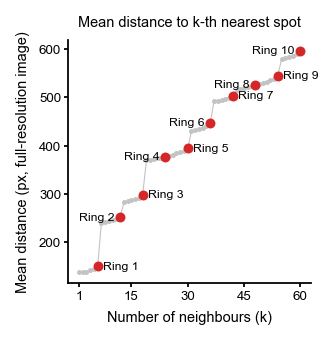

In [12]:
# 8. Sup. Fig. 9a: mean distance to the k-th nearest spot (12 cell 17)
fig, ax = plt.subplots(figsize=(2.3, 2.1))
ax.plot(k_values, mean_distances, color="#c3c3c3", linewidth=0.5, zorder=0)
other = ~np.isin(k_values, list(ring_map))
ax.scatter(k_values[other], mean_distances[other], color="#c3c3c3", s=5, linewidths=0, zorder=1)

for k, ring in ring_map.items():
    ax.scatter(k, mean_distances[k - 1], color="#d62728", s=20, linewidths=0, zorder=3)
    # labels alternate sides so that neighbouring rings do not overlap
    ax.text(k + 1.5 if ring % 2 else k - 1.5, mean_distances[k - 1], f"Ring {ring}", fontsize=5.5,
            ha="left" if ring % 2 else "right", va="center")
ax.set_xticks(np.linspace(1, max_k, 5, dtype=int))
ax.set_xlabel("Number of neighbours (k)", fontsize=6.5)
ax.set_ylabel("Mean distance (px, full-resolution image)", fontsize=6.5)
ax.set_title("Mean distance to k-th nearest spot", fontsize=6.5)
ax.tick_params(labelsize=6, length=2, pad=1)
ax.set_box_aspect(1)
ax.grid(False)

sns.despine(ax=ax)
plt.tight_layout()
plt.savefig(figure_dir + "ExtendedDataFig7a_knn_distance.pdf", bbox_inches="tight")
plt.show()
panel_a.to_csv(source_dir + "ExtendedDataFig7a_knn_distance.csv", index=False)

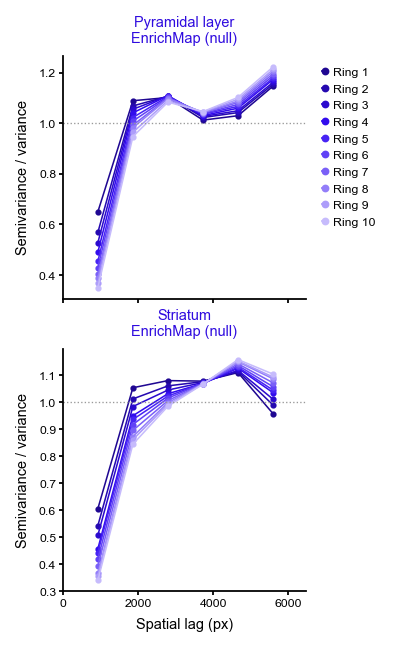

In [13]:
# 9. Sup. Fig. 9b: variograms per ring, compact (semivariance / variance) and full (semivariance)

def enrichmap_shades(n, lightest=0.86, darkest=0.30):
    """
    Generate n shades of the EnrichMap hue from dark to light (one per ring).

    Parameters
    ----------
    n : int
        Number of shades.
    lightest, darkest : float
        HLS lightness range.

    Returns
    -------
    list of str
        Hex colors.
    """
    base = colours["EnrichMap (null)"]
    h, _, s = colorsys.rgb_to_hls(
        *(int(base[i:i + 2], 16) / 255 for i in (1, 3, 5))
    )

    return [
        "#%02x%02x%02x" % tuple(
            round(v * 255)
            for v in colorsys.hls_to_rgb(h, lightness, s)
        )
        for lightness in np.linspace(darkest, lightest, n)
    ]


ring_shades = dict(zip(rings, enrichmap_shades(len(rings))))  # Ring 1 darkest


# ---------------------------------------------------------------------------
# Compact version: normalized semivariance (semivariance / variance)
# ---------------------------------------------------------------------------

fig, axes = plt.subplots(
    len(regions),
    len(variant_keys),
    figsize=(4, 4),
    sharex=True,
    squeeze=False
)

for i, ct in enumerate(regions):
    vg = variograms[
        (variograms["region"] == region_labels[ct])
        & variograms["inside_plotted_x_range"]
    ]

    for j, v in enumerate(variant_keys):
        ax = axes[i, j]

        for ring in rings:
            g = vg[
                (vg["method"] == v)
                & (vg["ring"] == ring)
            ]

            if g.empty:
                continue

            ax.plot(
                g["lag_bin_upper_edge_px"],
                g["semivariance / variance"],
                "o-",
                color=ring_shades[ring],
                ms=1.8,
                lw=0.7,
                label=f"Ring {ring}"
            )

        ax.axhline(
            1,
            ls=":",
            c="0.6",
            lw=0.6
        )

        ax.set_xlim(0, max_lag)
        ax.set_title(
            f"{region_labels[ct]}\n{v}",
            fontsize=6.5,
            color=colours[v]
        )
        ax.tick_params(labelsize=5.5, length=2, pad=1)
        ax.grid(False)
        ax.set_box_aspect(1)
        sns.despine(ax=ax)

    axes[i, 0].set_ylabel(
        "Semivariance / variance",
        fontsize=6.5
    )

for ax in axes[-1, :]:
    ax.set_xlabel("Spatial lag (px)", fontsize=6.5)

# Explicit handles ensure all rings appear even if some have no observations.
handles = [
    Line2D(
        [0], [0],
        marker="o",
        color=ring_shades[r],
        ms=2.5,
        lw=0.8,
        label=f"Ring {r}"
    )
    for r in rings
]

axes[0, -1].legend(
    handles=handles,
    frameon=False,
    fontsize=5.5,
    loc="upper left",
    bbox_to_anchor=(1.02, 1.0)
)

plt.tight_layout(w_pad=0.5, h_pad=0.6)

plt.savefig(
    figure_dir + "ExtendedDataFig7b_variograms.pdf",
    bbox_inches="tight"
)

plt.show()

variograms.to_csv(
    source_dir + "ExtendedDataFig7b_variograms.csv",
    index=False
)

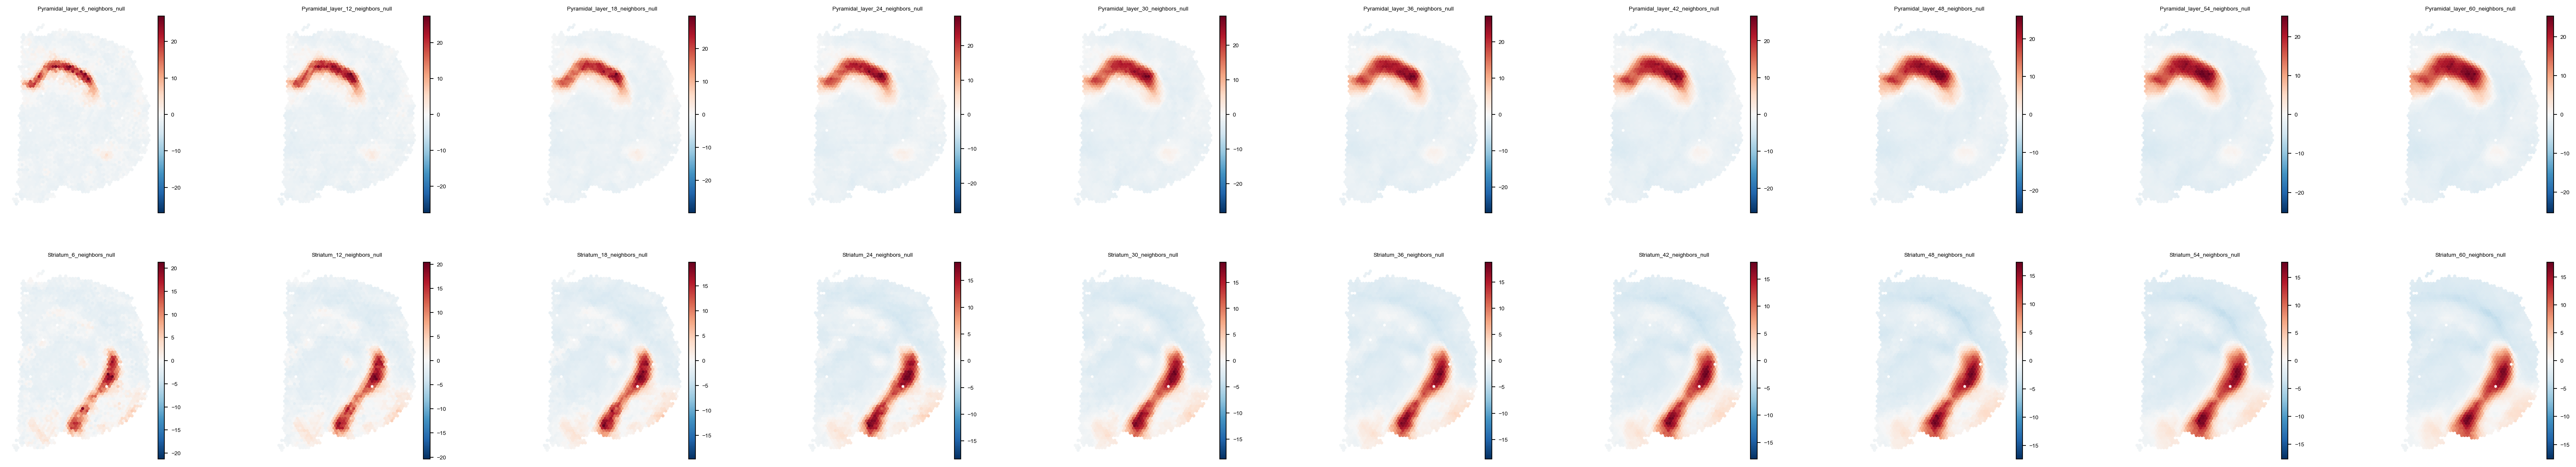

In [14]:
# 10. Extended Data Fig. 7c: score maps per ring (12 cell 14), centred at 0; rows = regions, columns = rings 1-10
keys = [f"{ct}_{6 * ring}_neighbors_{v}_score" for ct in regions for v in variants for ring in rings]
em.pl.spatial_enrichmap(adata, score_key=keys, vcenter=0, ncols=10, save="ExtendedDataFig7c_maps.pdf", shape=None,
                        size=spot_size)
maps = adata.obs[keys].copy()
maps.insert(0, "y", coords[:, 1])
maps.insert(0, "x", coords[:, 0])
maps.to_csv(source_dir + "ExtendedDataFig7c_maps.csv")

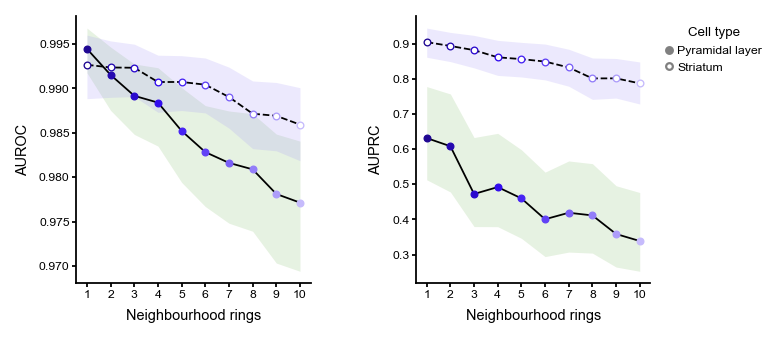

In [15]:
# 11. Extended Data Fig. 7d: AUROC and AUPRC per ring (filled, solid: pyramidal layer; open, dashed: striatum; bands: 95%
# bootstrap interval; markers: the ring colours of panel b)
band_colours = {regions[0]: "#86bf6e", regions[1]: "#a393f8"}
v = list(variant_keys)[0]
fig, axes = plt.subplots(1, 2, figsize=(4.6, 2.2), sharex=True, gridspec_kw={"wspace": 0.45})
for ax, metric in zip(axes, ["AUROC", "AUPRC"]):
    for ct, is_open in zip(regions, (False, True)):
        d = ring_metrics[(ring_metrics["region"] == region_labels[ct]) & (ring_metrics["method"] == v)].sort_values("ring")
        ax.fill_between(d["ring"], d[f"{metric}_lo"], d[f"{metric}_hi"], color=band_colours[ct], alpha=0.2, linewidth=0)
        ax.plot(d["ring"], d[metric], "--" if is_open else "-", color="k", lw=0.8, zorder=2)
        for _, r in d.iterrows():
            ax.plot(r["ring"], r[metric], "o", ms=3, color=ring_shades[int(r["ring"])],
                    mfc="white" if is_open else ring_shades[int(r["ring"])], mew=0.6, zorder=3)
    ax.set_xticks(rings)
    ax.set_xlabel("Neighbourhood rings", fontsize=6.5)
    ax.set_ylabel(metric, fontsize=6.5)
    ax.tick_params(labelsize=5.5, length=2, pad=1)
    ax.grid(False)
    sns.despine(ax=ax)
handles = [Line2D([0], [0], marker="o", color="0.5", ms=3, ls="", label=region_labels[regions[0]]),
           Line2D([0], [0], marker="o", color="0.5", mfc="white", ms=3, ls="", label=region_labels[regions[1]])]
axes[1].legend(handles=handles, frameon=False, fontsize=5.5, title="Cell type", title_fontsize=6, loc="upper left",
               bbox_to_anchor=(1.02, 1.0))
plt.savefig(figure_dir + "ExtendedDataFig7d_ring_recovery.pdf", bbox_inches="tight")
plt.show()
ring_metrics[ring_metrics["method"] == v].assign(
    signature_genes=lambda df: df["region"].map({region_labels[ct]: len(signatures_dict[ct]) for ct in regions})
).to_csv(source_dir + "ExtendedDataFig7d_ring_recovery.csv", index=False)